[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C2_NB04_active_rotator_network.ipynb)

# Day 1 · Chapter 2 · Notebook 04 — A network of active rotators: synchronisation

**Goal.** Couple thousands of phase units (NB02) and watch them **synchronise**. We introduce the
**Kuramoto order parameter**, the single number that summarises a whole population of phases, and we make
**videos** of the units moving on the circle. Finally we lay the same units on a sheet and see that the
**wiring** alone decides between travelling waves and a population that fires as one.

This is the network studied by Buendía et al. (2021), which we will meet again in Chapter 4 to discuss
dynamical regimes and criticality.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import networks
from src.plotting import phase_movie, show_movie
os.makedirs('../figures/videos', exist_ok=True)

## 1. The model

$N$ active rotators (NB02), all-to-all coupled, each with its own noise:

$$
\frac{d\varphi_j}{dt} = \omega + a\sin\varphi_j + \frac{J}{N}\sum_{k=1}^{N}\sin(\varphi_k-\varphi_j) + \sigma\,\xi_j(t)
$$

* $\omega$, $a$: the single unit (oscillatory if $a<\omega$, excitable if $a>\omega$).
* $J$: coupling. The term $\sin(\varphi_k-\varphi_j)$ speeds up unit $j$ if unit $k$ is slightly ahead
  and slows it down if $k$ is behind: **every unit is pulled toward the others**.
* $\sigma\,\xi_j(t)$: independent white noise on every unit, which pushes the phases apart.
* With $a=0$ this is the (noisy) **Kuramoto model** (Kuramoto 1975, 1984), the classic model of synchronisation
  of fireflies, pacemaker cells, power grids, metronomes... and neurons.

**Connectivity: all-to-all**, as in NB03: every unit sees every other with weight $J/N$.

### The Kuramoto order parameter

Represent each unit as a point $e^{i\varphi_j}$ on the unit circle and take the centre of mass:

$$
Z(t) = R(t)\,e^{i\Psi(t)} = \frac1N\sum_{j=1}^N e^{i\varphi_j(t)}
$$

* $R\in[0,1]$: **coherence**. $R\approx 0$ when phases are spread around the circle, $R=1$ when all units have the same phase.
* $\Psi$: the average phase.

**A key identity.** The coupling term can be rewritten with $Z$:

$$
\frac{J}{N}\sum_k\sin(\varphi_k-\varphi_j) = J\,R\,\sin(\Psi-\varphi_j)
$$

Each unit does not need to know about every other unit: it only feels the **mean field** $Z$.
This is why all-to-all networks can be reduced to a few equations (Chapter 3), and why the simulation is
fast: the cost is $N$ per step, not $N^2$.

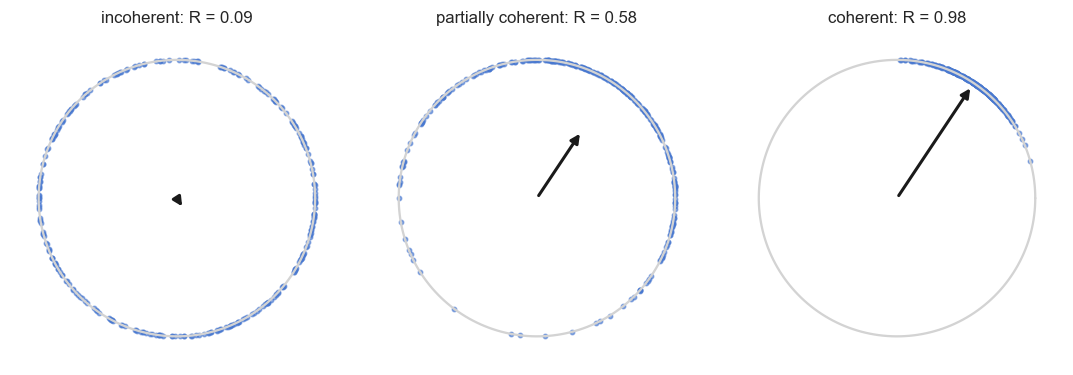

In [2]:
rng = np.random.default_rng(0)
examples = {"incoherent": rng.uniform(0, 2 * np.pi, 300),
            "partially coherent": rng.vonmises(1.0, 1.5, 300),
            "coherent": rng.vonmises(1.0, 20.0, 300)}
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
c = np.linspace(0, 2 * np.pi, 200)
for a_, (name, ph) in zip(ax, examples.items()):
    Z = np.mean(np.exp(1j * ph))
    a_.plot(np.cos(c), np.sin(c), c="lightgray")
    a_.scatter(np.cos(ph), np.sin(ph), s=8, alpha=0.6)
    a_.annotate("", xy=(Z.real, Z.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
    a_.set(aspect="equal", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), title=f"{name}: R = {abs(Z):.2f}"); a_.axis("off")
plt.tight_layout()

## 2. Kuramoto units ($a=0$): the synchronisation transition

Identical oscillators ($\omega=1$) with noise $\sigma=0.5$. Without coupling, noise spreads the phases.
With strong coupling they lock together. Video first: units start at random phases, $J=1$.

In [3]:
t, Z, ph = networks.active_rotator_network(N=2000, a=0.0, J=1., sigma=0.5, T=40, dt=0.01, rec_dt=0.1, n_rec=300, seed=1)
anim = phase_movie(t, ph, Z, n_show=300, stride=1, title="Kuramoto, J = 1, σ = 0.5")
show_movie(anim, save_as="../figures/videos/NB04_kuramoto_sync.mp4")

Starting from incoherence ($R\approx 0$), the units gather into a cluster that rotates at speed $\omega$,
and $R$ grows to ~0.9. Noise keeps the cluster from collapsing to a single point.

**How much coupling is needed?** We sweep $J$ and measure the stationary coherence.
For identical noisy oscillators the theory predicts a **critical coupling** $J_c=\sigma^2$: below it the
incoherent state is stable, above it a coherent cluster appears, with $R$ given by the self-consistency
equation $R = I_1(x)/I_0(x)$, $x=2JR/\sigma^2$ ($I_n$: modified Bessel functions).

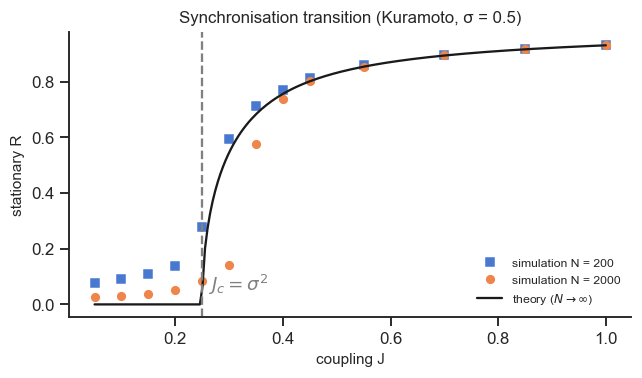

In [4]:
from scipy.special import i0e, i1e
from scipy.optimize import brentq

sigma = 0.5
def R_theory(J):
    f = lambda R: R - i1e(2 * J * R / sigma**2) / i0e(2 * J * R / sigma**2)
    return brentq(f, 1e-6, 1.0) if J > sigma**2 else 0.0

Js = np.r_[np.linspace(0.05, 0.45, 9), np.linspace(0.55, 1.0, 4)]
fig, ax = plt.subplots(figsize=(6, 3.6))
for N, mk in [(200, "s"), (2000, "o")]:
    R_sim = []
    for J in Js:
        t, Z, _ = networks.active_rotator_network(N=N, a=0.0, J=J, sigma=sigma, T=150, dt=0.01, n_rec=1, seed=2)
        R_sim.append(np.abs(Z[t > 50]).mean())
    ax.plot(Js, R_sim, mk, ms=5, label=f"simulation N = {N}")
Jt = np.linspace(0.05, 1.0, 200)
ax.plot(Jt, [R_theory(J) for J in Jt], "k", label=r"theory ($N\to\infty$)")
ax.axvline(sigma**2, c="gray", ls="--"); ax.text(sigma**2 + 0.01, 0.05, r"$J_c=\sigma^2$", color="gray")
ax.set(xlabel="coupling J", ylabel="stationary R", title="Synchronisation transition (Kuramoto, σ = 0.5)")
ax.legend(fontsize=8)
plt.tight_layout()

This is a **phase transition**, like a magnet magnetising: a smooth change of a
parameter ($J$) makes a macroscopic, collective order appear. Below $J_c$, $R$ is not exactly zero for finite
$N$ (it is of order $1/\sqrt N$): finite networks blur the transition. Just above $J_c$ the large network
lags behind the theory: close to the transition the dynamics become very slow (*critical slowing down*) and
our 150 time units are not enough to reach the stationary state. Phase transitions and their
"critical point" are the topic of Chapter 4.

## 3. Active rotators ($a\neq 0$): excitable units that fire together

Now each unit is close to its SNIC ($a\approx\omega$), so it behaves like an excitable neuron (NB02):
it rests and fires a spike (a fast turn around the circle, red star at $\varphi=\pi/2$) when noise or its
neighbours push it over threshold. We fix $\omega=1$, $J=1$ and change $a$ and $\sigma$.

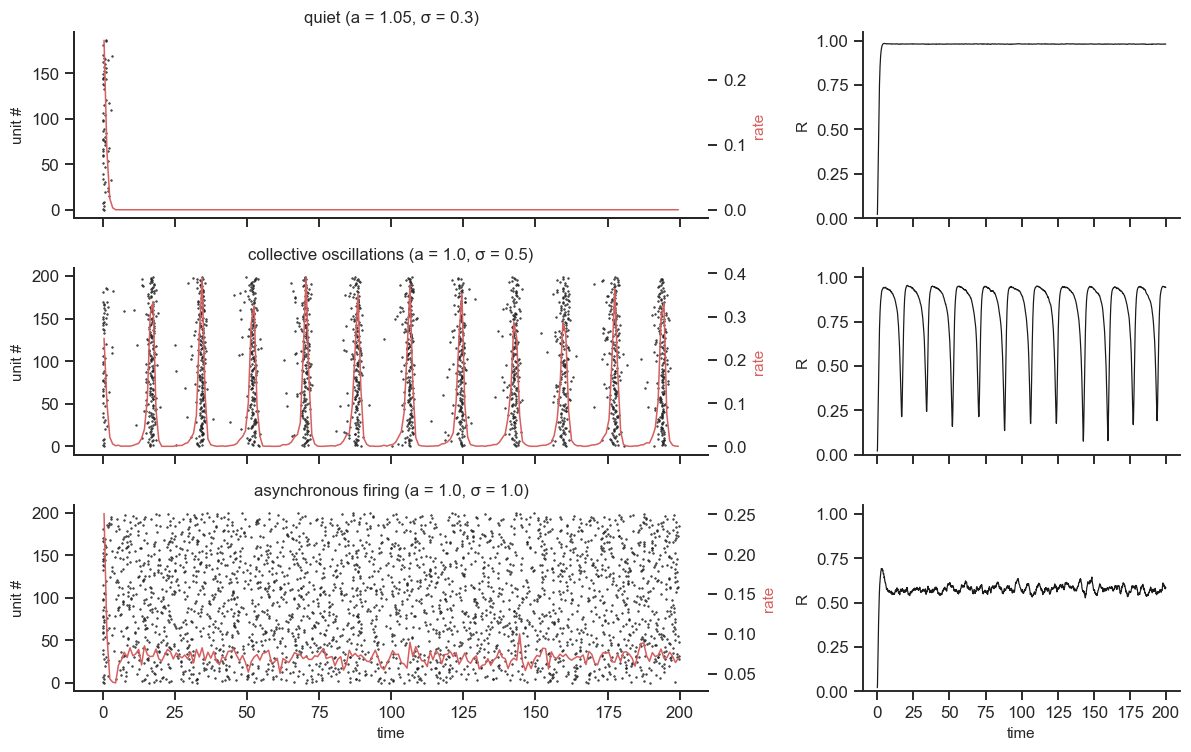

In [5]:
regimes = {"quiet (a = 1.05, σ = 0.3)": (1.05, 0.3),
           "collective oscillations (a = 1.0, σ = 0.5)": (1.0, 0.5),
           "asynchronous firing (a = 1.0, σ = 1.0)": (1.0, 1.0)}
fig, ax = plt.subplots(3, 2, figsize=(11, 7), sharex=True, gridspec_kw=dict(width_ratios=[2, 1]))
sims = {}
for row, (name, (a, s)) in enumerate(regimes.items()):
    t, Z, ph = networks.active_rotator_network(N=2000, a=a, J=1.0, sigma=s, T=200, dt=0.01, rec_dt=0.1, n_rec=2000, seed=3)
    sims[name] = (t, Z, ph)
    st, si = networks.phase_raster(t, ph)
    keep = si < 200
    ax[row, 0].plot(st[keep], si[keep], ".k", ms=1)
    ax[row, 0].set(ylabel="unit #", title=name)
    rate = np.histogram(st, bins=np.arange(0, 200.1, 1.0))[0] / 2000
    ax2 = ax[row, 0].twinx(); ax2.plot(np.arange(0.5, 200, 1.0), rate, "C3", lw=1); ax2.set_ylabel("rate", color="C3")
    ax[row, 1].plot(t, np.abs(Z), "k", lw=0.8); ax[row, 1].set(ylabel="R", ylim=(0, 1.05))
ax[-1, 0].set_xlabel("time"); ax[-1, 1].set_xlabel("time")
plt.tight_layout()

* **Quiet.** Units sit at rest and almost never fire. Note that $R\approx 1$: all units sit at the *same*
  resting phase, so they are "coherent" without oscillating. **High $R$ does not mean oscillation.**
* **Collective oscillations.** Units rest, then fire **together** in a population spike, then rest again: the
  rate and $R$ oscillate. Noise triggers a few units, the coupling recruits the others.
* **Asynchronous firing.** Strong noise: units fire often but independently; rate and $R$ are flat.

The same units, with the same coupling, show three qualitatively different collective behaviours.
Watch the collective oscillations:

In [7]:
t, Z, ph = sims["collective oscillations (a = 1.0, σ = 0.5)"]
sel = t < 60
anim = phase_movie(t[sel], ph[sel], Z[sel], n_show=300, stride=1, spike_phase=np.pi / 2,
                   title="active rotators, a = 1, σ = 0.5, J = 1")
show_movie(anim, save_as="../figures/videos/NB04_active_rotators_oscillation.mp4")

### Explore: the regimes of the active-rotator network

$N=1000$ units, $\omega=1$. Left: raster of 150 units and population rate. Right: a snapshot of the phases
at the end of the run.

* With $J=1$, start from $a=1.05$, $\sigma=0.3$ (quiet) and increase $\sigma$ slowly. When do population spikes appear? When do they dissolve into asynchronous firing?
* Set $J=0$. Can you still get collective oscillations? What does this tell you about where they come from?
* Set $a=0$ (Kuramoto) and find the critical $J$ for $\sigma=0.6$. Compare with $J_c=\sigma^2$.

In [6]:
@interact(a=slider(1.05, 0.0, 1.3, 0.01, "tilt a"),
          sigma=slider(0.3, 0.0, 1.2, 0.02, "noise sigma"),
          J=slider(1.0, 0.0, 3.0, 0.05, "coupling J"))
def explore_rotators(a, sigma, J):
    t, Z, ph = networks.active_rotator_network(N=1000, a=a, J=J, sigma=sigma, T=150, dt=0.01, rec_dt=0.1, n_rec=1000, seed=4)
    st, si = networks.phase_raster(t, ph)
    fig = plt.figure(figsize=(12, 3.6))
    ax0 = fig.add_subplot(1, 3, (1, 2))
    keep = si < 150
    ax0.plot(st[keep], si[keep], ".k", ms=1); ax0.set(xlabel="time", ylabel="unit #")
    rate = np.histogram(st, bins=np.arange(0, 150.1, 1.0))[0] / 1000
    ax2 = ax0.twinx(); ax2.plot(np.arange(0.5, 150, 1.0), rate, "C3", lw=1); ax2.set_ylabel("rate", color="C3")
    ax0.set_title(f"rate per unit {len(st) / 1000 / 150:.3f},  R: mean {np.abs(Z[t > 30]).mean():.2f}, std {np.abs(Z[t > 30]).std():.2f}")
    ax1 = fig.add_subplot(1, 3, 3)
    c = np.linspace(0, 2 * np.pi, 200)
    ax1.plot(np.cos(c), np.sin(c), c="lightgray"); ax1.plot(0, 1, "*", c="C3", ms=12)
    ax1.scatter(np.cos(ph[-1, :300]), np.sin(ph[-1, :300]), s=8, alpha=0.6)
    ax1.annotate("", xy=(Z[-1].real, Z[-1].imag), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
    ax1.set(aspect="equal", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), title="phases at the end"); ax1.axis("off")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=1.05, continuous_update=False, description='tilt a', layout=Layout(wid…

## 4. Space: the same rotators on a sheet

So far every unit felt **every other unit** (all-to-all). Now we put the same excitable rotators on a square
sheet of $L\times L$ units and let each unit feel only its **neighbours**, the units inside a square of side
$2R+1$ around it:

$$
\frac{d\varphi_j}{dt} = \omega + a\sin\varphi_j + J\,\big\langle \sin(\varphi_k-\varphi_j)\big\rangle_{k\ \text{near}\ j} + \sigma\,\xi_j(t)
$$

This is the equation of section 1 with one change: the average $\frac1N\sum_k$ over the **whole** network becomes an
average over the **neighbourhood**. The identity of section 1 still holds, but with a *local* order parameter
$Z_j=\langle e^{i\varphi_k}\rangle_{k\ \text{near}\ j}$: each unit is pulled toward the average phase **around it**.

* $R=1$: the 8 nearest neighbours.
* $R$ as large as the sheet: every unit sees the same $Z$, and we are back to the all-to-all network of section 3.

The units are **excitable** ($a=1.01>\omega=1$) and noisy: alone, each one rests and fires now and then.
The simulator `networks.rotator_sheet` is about 15 lines of numpy; the neighbourhood average is a moving average
(`uniform_filter`) of $\cos\varphi$ and $\sin\varphi$.

### Same units, same coupling strength, different wiring
Two sheets of $100\times100$ units with identical $a$, $J$ and $\sigma$. Left: neighbours only ($R=1$).
Right: all-to-all. Colour is $\sin\varphi$: **bright = the unit is spiking**, dark = at rest.

In [7]:
from src.plotting import sheet_movie, sheet_playground
pars = dict(L=100, a=1.01, J=2.0, sigma=0.4, T=150, rec_dt=0.5, seed=1)
t, ph_local, rate_local, _ = networks.rotator_sheet(R=1, **pars)      # neighbours only
t, ph_all, rate_all, _ = networks.rotator_sheet(R=None, **pars)       # all-to-all
anim = sheet_movie(t, [ph_local, ph_all], [rate_local, rate_all],
                   ["neighbours only (R = 1)", "all-to-all"], stride=1)
show_movie(anim, save_as="../figures/videos/NB04_sheet_local_vs_all.mp4")

* **Neighbours only.** Noise fires a unit here and there; its spike pushes the neighbours over threshold, they push
  theirs, and the activity spreads as a **travelling wave**. Behind a wave the units are returning to rest and
  cannot fire again at once, so two waves that collide annihilate. The sheet is strongly organised in space, but
  the rate of the whole sheet shows only small, broad bumps (check the y-axis: about ten times lower than on the
  right) that fade once the common start at rest is forgotten: waves start at random places and times, and their
  contributions largely average out.
* **All-to-all.** There is no "nearby". A few noisy spikes nudge **everyone** a little, the whole sheet is recruited
  at once, and the rate shows large population spikes: the collective oscillations of section 3.

**Lesson.** Coupling is not only *how strong* ($J$) but also *who talks to whom*. Same units, same $J$, same
noise: the wiring alone decides between travelling waves and a sheet that fires as one.

### Spirals: a broken wave becomes a pacemaker
Almost no noise ($\sigma=0.02$). We kick a small disc in the centre: a ring wave expands. At $t=40$ we erase the
left half of the sheet (put it back at rest). The two free ends of the broken wave curl up.

In [8]:
p = dict(L=100, a=1.01, J=2.0, sigma=0.02, R=1, rec_dt=0.5)
rest = np.pi + np.arcsin(1 / p["a"])                       # resting phase of an excitable rotator (NB02)
kick = 2 * np.pi - np.arcsin(1 / p["a"]) + 0.8             # just past the threshold
phi0 = np.full((100, 100), rest)
y, x = np.mgrid[:100, :100]
phi0[(x - 50) ** 2 + (y - 50) ** 2 < 36] = kick            # kick a disc in the centre
t1, ph1, r1, phi = networks.rotator_sheet(T=40, phi0=phi0, seed=2, **p)
phi[:, :50] = rest                                         # the cut: erase the left half
t2, ph2, r2, _ = networks.rotator_sheet(T=160, phi0=phi, seed=3, **p)
anim = sheet_movie(np.r_[t1, 40 + t2], [np.concatenate([ph1, ph2])], [np.r_[r1, r2]],
                   ["kick in the centre, cut at t = 40"], stride=2)
show_movie(anim, save_as="../figures/videos/NB04_sheet_spirals.mp4")

Each free end winds into a rotating **spiral** that keeps re-exciting the sheet by itself: a self-sustained
pacemaker made of units that, alone, would never fire. Spiral waves are seen in heart muscle (where they underlie
fibrillation), in chemical reactions (Belousov–Zhabotinsky), and in slices and recordings of cortex
(Huang et al. 2010; Muller et al. 2018).

### Explore: a live sheet
The sheet below runs **live** in your browser: $128\times128$ rotators with the same equation (written in
JavaScript so that it can run in real time while you move the sliders). Click or drag on the sheet to kick units.

* Press **Waves**. Then move the **wiring radius** slowly from 1 to "all". When do the waves give way to flashes of
  the whole sheet? Watch the rate trace.
* Press **No coupling**: units fire alone, like salt and pepper. Raise $J$ slowly: when do spikes start to spread?
* Press **Spirals** and wait for the cut. Then make your own: click to start a ring, wait, press **Cut**.
* Set $a<1$: the units are now oscillators (NB02). What does the sheet do?
* With **Waves**, raise the noise $\sigma$ towards 0.8. Do the waves survive?

In [11]:
sheet_playground()

### Why this matters for the next chapter
In Chapter 3 we will describe a whole population with **one** variable, $Z(t)$. That works for all-to-all
networks, where every unit feels the same $Z$. With local wiring each unit feels its own $Z_j$: we would need a
**field** $Z(x,t)$ that changes in space as well as in time (neural field models, Amari 1977), which is beyond this
course. Choosing all-to-all is a modelling choice: a map that keeps the collective rhythm of a population and
leaves out space.

## 5. Take-home

* Coupled phase units synchronise: above a critical coupling a collective order ($R>0$) appears, a phase transition.
* The order parameter $Z=Re^{i\Psi}$ summarises the population, and each unit only feels $Z$.
* With excitable units, the same network shows quiet, oscillatory and asynchronous regimes, controlled by $a$, $\sigma$ and $J$.
* Wiring matters: with neighbour coupling the same units make travelling waves and spirals; with all-to-all
  coupling the population fires as one, and only then can a single $Z(t)$ describe it.
* **Next (Chapter 3):** can we write equations for $Z(t)$ directly, as for the rate of the QIF network?

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. Repeat the synchronisation sweep of section 2 with $\sigma=0.3$ and $\sigma=0.7$. Does $J_c$ follow $\sigma^2$?
2. Give the Kuramoto units *different* natural frequencies, $\omega_j$ drawn from a Lorentzian of half-width $\gamma$, without noise (modify a copy of `networks.active_rotator_network`). Kuramoto's result is $J_c=2\gamma$. Check it.
3. In the collective-oscillation regime, measure the period of the population spikes for $\sigma=0.45, 0.5, 0.55$. What happens to the period as you approach the quiet regime?
4. Use the videos in `figures/videos/` in a short explanation (3 sentences) of why high $R$ does not always mean oscillation.
5. With `networks.rotator_sheet` ($R=1$, $\sigma=0.02$, a kick in the centre), measure the speed of the ring wave
   for $J=1, 2, 3$. How does the speed depend on the coupling?

### References
* Kuramoto Y (1984). *Chemical Oscillations, Waves, and Turbulence*. Springer.
* Strogatz SH (2000). From Kuramoto to Crawford: exploring the onset of synchronization in populations of coupled oscillators. *Physica D* 143:1–20.
* Shinomoto S, Kuramoto Y (1986). Phase transitions in active rotator systems. *Prog Theor Phys* 75:1105–1110.
* Buendía V, Villegas P, Burioni R, Muñoz MA (2021). Hybrid-type synchronization transitions: where incipient oscillations, scale-free avalanches, and bistability live together. *Phys Rev Research* 3:023224.
* Strogatz SH (2003). *Sync: The Emerging Science of Spontaneous Order*. Hyperion (popular science, great for students).
* Huang X, Xu W, Liang J, Takagaki K, Gao X, Wu JY (2010). Spiral wave dynamics in neocortex. *Neuron* 68:978–990.
* Muller L, Chavane F, Reynolds J, Sejnowski TJ (2018). Cortical travelling waves: mechanisms and computational
  principles. *Nat Rev Neurosci* 19:255–268.
* Amari S (1977). Dynamics of pattern formation in lateral-inhibition type neural fields. *Biol Cybern* 27:77–87.